In [1]:
import scanpy as sc
import numpy as np
import pandas as pd

a549 = sc.read_h5ad("../data/processed/a549_norm.h5ad")
print(a549.var.head())

                          id  num_cells_expressed-0-0  \
index                                                   
TSPAN6    ENSG00000000003.14                     4017   
DPM1      ENSG00000000419.12                     8442   
SCYL3     ENSG00000000457.13                     4386   
C1orf112  ENSG00000000460.16                     5998   
CFH       ENSG00000000971.15                    22191   

          num_cells_expressed-1-0  num_cells_expressed-1  n_cells_by_counts  \
index                                                                         
TSPAN6                      13320                    199               4017   
DPM1                        72353                  11231               8442   
SCYL3                       24120                   3380               4386   
C1orf112                    24454                   9555               5998   
CFH                          1452                  23434              22191   

          mean_counts  log1p_mean_counts  pct_

In [2]:
print(a549.var.head())

if "gene_short_name" in a549.var.columns:
    gene_names = a549.var["gene_short_name"].values
else:
    gene_names = a549.var_names.values

                          id  num_cells_expressed-0-0  \
index                                                   
TSPAN6    ENSG00000000003.14                     4017   
DPM1      ENSG00000000419.12                     8442   
SCYL3     ENSG00000000457.13                     4386   
C1orf112  ENSG00000000460.16                     5998   
CFH       ENSG00000000971.15                    22191   

          num_cells_expressed-1-0  num_cells_expressed-1  n_cells_by_counts  \
index                                                                         
TSPAN6                      13320                    199               4017   
DPM1                        72353                  11231               8442   
SCYL3                       24120                   3380               4386   
C1orf112                    24454                   9555               5998   
CFH                          1452                  23434              22191   

          mean_counts  log1p_mean_counts  pct_

In [3]:
#sanity check

drug = "Trametinib (GSK1120212)"
ctrl = a549[a549.obs["vehicle"] == 1]

for g in ["DUSP6", "SPRY4", "ETV5"]:
    idx = np.where(gene_names == g)[0]
    if len(idx) == 0:
        print(g, "not found")
        continue
    idx = idx[0]
    print(g, "control:", round(ctrl.X[:, idx].mean(), 3))
    for d in [10, 100, 1000, 10000]:
        cells = a549[(a549.obs["product_name"] == drug) & (a549.obs["dose"] == d)]
        print("   dose", d, ":", round(cells.X[:, idx].mean(), 3))

DUSP6 control: 0.029
   dose 10 : 0.0
   dose 100 : 0.0
   dose 1000 : 0.0
   dose 10000 : 0.0
SPRY4 control: 0.014
   dose 10 : 0.0
   dose 100 : 0.0
   dose 1000 : 0.0
   dose 10000 : 0.0
ETV5 control: 0.088
   dose 10 : 0.0
   dose 100 : 0.0
   dose 1000 : 0.0
   dose 10000 : 0.016


In [4]:
#Choosing the 2,000 genes
sc.pp.highly_variable_genes(a549, n_top_genes=2000)
print(a549.var["highly_variable"].sum())   # should be 2000

2000


In [5]:
#Check the marker genes
hvg_names = gene_names[a549.var["highly_variable"].values]
for g in ["DUSP6", "SPRY4", "ETV5"]:
    print(g, g in hvg_names)

DUSP6 False
SPRY4 False
ETV5 False


In [6]:
a549_hvg = a549[:, a549.var["highly_variable"]].copy()
print(a549_hvg.shape)   # (143008, 2000)

(143008, 2000)


In [7]:
#Average per group
groups = a549_hvg.obs["product_dose"]
rows = {}
meta = []

for g in groups.unique():
    cells = a549_hvg[groups == g]
    if cells.n_obs < 30:
        continue
    rows[g] = np.asarray(cells.X.mean(axis=0)).ravel()
    meta.append({
        "product_dose": g,
        "product_name": cells.obs["product_name"].iloc[0],
        "dose": cells.obs["dose"].iloc[0],
        "n_cells": cells.n_obs,
    })

pb = pd.DataFrame.from_dict(rows, orient="index", columns=hvg_names)
meta = pd.DataFrame(meta).set_index("product_dose")
print(pb.shape)
print("groups dropped:", groups.nunique() - len(pb))

(751, 2000)
groups dropped: 2


In [8]:
ctrl_name = meta.index[meta["dose"] == 0][0]
print("control:", ctrl_name)

delta = pb.drop(ctrl_name) - pb.loc[ctrl_name]
meta = meta.drop(ctrl_name)
print(delta.shape)

control: Vehicle_0
(750, 2000)


In [9]:
strength = delta.abs().mean(axis=1)
meta["strength"] = strength
print(meta.sort_values("strength", ascending=False).head(10))

                                                          product_name  \
product_dose                                                             
Dacinostat (LAQ824)_10000                          Dacinostat (LAQ824)   
Quisinostat (JNJ-26481585) 2HCl_10000  Quisinostat (JNJ-26481585) 2HCl   
Givinostat (ITF2357)_10000                        Givinostat (ITF2357)   
Trichostatin A (TSA)_10000                        Trichostatin A (TSA)   
Panobinostat (LBH589)_10000                      Panobinostat (LBH589)   
Pracinostat (SB939)_10000                          Pracinostat (SB939)   
Panobinostat (LBH589)_1000                       Panobinostat (LBH589)   
AR-42_10000                                                      AR-42   
Quisinostat (JNJ-26481585) 2HCl_1000   Quisinostat (JNJ-26481585) 2HCl   
CUDC-907_10000                                                CUDC-907   

                                          dose  n_cells  strength  
product_dose                               

In [10]:
delta.to_csv("../data/processed/response_delta.csv")
meta.to_csv("../data/processed/response_meta.csv")

In [11]:
dropped = set(groups.unique()) - set(pb.index)
print(dropped)

{'YM155 (Sepantronium Bromide)_10000', 'Bisindolylmaleimide IX (Ro 31-8220 Mesylate)_10000'}


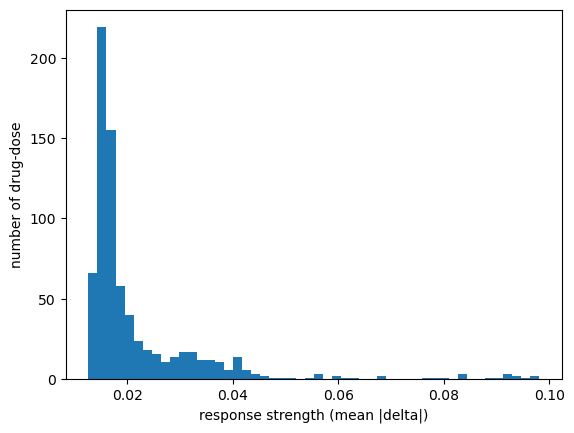

count    750.000000
mean       0.022136
std        0.013242
min        0.012644
25%        0.015336
50%        0.016942
75%        0.022934
max        0.098123
Name: strength, dtype: float64


In [12]:
import matplotlib.pyplot as plt

plt.hist(meta["strength"], bins=50)
plt.xlabel("response strength (mean |delta|)")
plt.ylabel("number of drug-dose")
plt.savefig("../results/figures/03_strength_hist.png", dpi=150)
plt.show()

print(meta["strength"].describe())

In [13]:
ctrl = a549_hvg[a549_hvg.obs["vehicle"] == 1]
ctrl_mean = pb.loc[ctrl_name].values

fake = []
for i in range(20):
    idx = np.random.choice(ctrl.n_obs, 190, replace=False)
    m = np.asarray(ctrl.X[idx].mean(axis=0)).ravel()
    fake.append(np.abs(m - ctrl_mean).mean())

print("noise floor mean:", np.mean(fake))
print("noise floor max:", np.max(fake))

noise floor mean: 0.014375968
noise floor max: 0.015283108


In [14]:
fake = []
for i in range(20):
    perm = np.random.permutation(ctrl.n_obs)
    a = perm[:100]      # fake "drug" group
    b = perm[100:]      # the rest = control
    ma = np.asarray(ctrl.X[a].mean(axis=0)).ravel()
    mb = np.asarray(ctrl.X[b].mean(axis=0)).ravel()
    fake.append(np.abs(ma - mb).mean())

threshold = np.max(fake)
print("noise floor mean:", round(np.mean(fake), 4))
print("noise floor max:", round(threshold, 4))

meta["responder"] = meta["strength"] > threshold
print(meta["responder"].sum(), "responders out of", len(meta))

noise floor mean: 0.0206
noise floor max: 0.0215
209 responders out of 750


In [15]:
meta.to_csv("../data/processed/response_meta.csv")